# Intial Configuration

## Importing libraries 

In [2]:
import os
import re
import shutil
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2


from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

In [3]:
!pip install -q -U mediapipe
import mediapipe as mp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 MB 51.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 6.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


## Configuration

In [4]:
RAW_DIR = Path(
"/kaggle/input/datasets/rahulbiswasmtech/masked-and-unmasked-dataset/dataset"
)

SPLIT_DIR = Path("/kaggle/working/dataset_split")
MODEL_DIR = "/kaggle/working/mask_mobilenetv2"
IDENTITY_CACHE = Path("/kaggle/working/identity_upperface_cache")




IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Number of visually similar candidates considered

HARD_NEGATIVE_TOP_K = 10

# For MobileNet V2
EPOCHS = 15
LR = 1e-5


random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [5]:
os.makedirs(MODEL_DIR, exist_ok=True)
IDENTITY_CACHE.mkdir(parents=True,exist_ok=True)

## Identity Extraction

In [6]:
def get_identity(filename):

    stem = Path(filename).stem #removes the file extension (.png ,.jpg etc)
    m = re.match(r"^(?:UM|M)(\d{3})\d$", stem)

    if m is None:
        raise ValueError(f"Invalid filename: {filename}")
        
    return m.group(1)

In [7]:

# IMAGE QUALITY ASSESSMENT

def assess_image_quality(image):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 1. Noise estimation
    smoothed = cv2.GaussianBlur(gray, (5, 5), 0)

    residual = (
        gray.astype(np.float32) -
        smoothed.astype(np.float32)
    )

    noise_score = np.median(np.abs(residual)) / 0.6745

    # 3. Brightness assessment
    brightness = np.mean(gray)

    # Initial thresholds: calibrate against your dataset
    is_noisy = noise_score > 15
    is_dark = brightness < 50
    is_overexposed = brightness > 220

    acceptable = not (
        is_noisy or
        is_dark or is_overexposed
    )

    return acceptable, {
        "noise_score": noise_score,
        "brightness": brightness
    }


In [14]:

# IDENTITY EXTRACTION WITH IMAGE QUALITY CHECK

identity_files = {}

# Track rejected images
rejected_images = []

for mask_type in ["Masked", "UnMasked"]:

    for path in (RAW_DIR / mask_type).glob("*.png"):

        # Load original image
        image = cv2.imread(str(path))

        if image is None:
            rejected_images.append((str(path), "Unreadable"))
            continue

        # Assess image quality
        acceptable, quality = assess_image_quality(image)

        if not acceptable:

            reasons = []

            if quality["noise_score"] > 15:
                reasons.append("Noisy")

            if quality["brightness"] < 35:
                reasons.append("Dark")

            if quality["brightness"] > 230:
                reasons.append("Overexposed")

            rejected_images.append(
                (str(path), ", ".join(reasons))
            )

            continue

        # Original identity extraction logic
        identity = get_identity(path.name)

        identity_files.setdefault(
            identity,
            {
                "Masked": [],
                "UnMasked": []
            }
        )

        identity_files[identity][mask_type].append(path)

identities = sorted(identity_files)

print("Total identities retained:", len(identity_files))
print("Rejected images:", len(rejected_images))

for path, reason in rejected_images:
    print(path, ":", reason)


Total identities retained: 112
Rejected images: 0


## Identity-Level Split

In [15]:
train_ids, temp_ids = train_test_split(
    identities,
    test_size=0.30,
    random_state=SEED
)

valid_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=SEED
)


splits = {
    "train": sorted(train_ids),
    "valid": sorted(valid_ids),
    "test": sorted(test_ids)
}


print("Split sizes:", {k: len(v) for k, v in splits.items()})

Split sizes: {'train': 78, 'valid': 17, 'test': 17}


In [16]:
# Checking if splits are disjoint or not

assert set(train_ids).isdisjoint(valid_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)

print(" No identity overlap between splits.")



 No identity overlap between splits.


### Create manifest.json and Split Dataset directory

In [17]:
# Creating manifest.json

with open("identity_split_manifest.json","w") as f:
    json.dump(splits, f, indent=2)



# Creating a split dataset

if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)


for split, ids in splits.items():

    for mask_type in ["Masked", "UnMasked"]:

        dst_dir = (SPLIT_DIR /split /mask_type)

        dst_dir.mkdir(parents=True,exist_ok=True)

        for identity in ids:
            for src in identity_files[identity][mask_type]:
                shutil.copy2(src,dst_dir / src.name)


print(f"\nDataset created at: {SPLIT_DIR}")


Dataset created at: /kaggle/working/dataset_split


# Data Pre-processing

## Fetching Dataset

In [18]:

mask_train_ds = tf.keras.utils.image_dataset_from_directory(

    SPLIT_DIR / "train",

    labels="inferred",
    label_mode="binary",

    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    shuffle=True,
    seed=SEED
)


mask_valid_ds = tf.keras.utils.image_dataset_from_directory(

    SPLIT_DIR / "valid",

    labels="inferred",
    label_mode="binary",

    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    shuffle=False
)


mask_test_ds = tf.keras.utils.image_dataset_from_directory(

    SPLIT_DIR / "test",

    labels="inferred",
    label_mode="binary",

    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    shuffle=False
)

Found 462 files belonging to 2 classes.


I0000 00:00:1793907833.986709      76 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793907833.990166      76 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 100 files belonging to 2 classes.
Found 98 files belonging to 2 classes.


## Image Normalization and creating normalized dataset

In [19]:
def prepare_mask_ds(ds):

    return (ds.map(
                    lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
                                            num_parallel_calls=tf.data.AUTOTUNE
                ).prefetch(tf.data.AUTOTUNE)
           )


mask_train_ds = prepare_mask_ds(mask_train_ds)
mask_valid_ds = prepare_mask_ds(mask_valid_ds)
mask_test_ds = prepare_mask_ds(mask_test_ds)


print("Mask dataset ready.")
print("Classes:", ["Masked", "UnMasked"])

Mask dataset ready.
Classes: ['Masked', 'UnMasked']


## Intializing Mediapipe

In [20]:
# Downloading and storing face_landmarker.task model

MODEL_PATH = "/kaggle/working/face_landmarker.task"
if not os.path.exists(MODEL_PATH):

    !wget -q -O /kaggle/working/face_landmarker.task \
    https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task

print("Face Landmarker model ready.")

# Mediapipe configuration

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=MODEL_PATH
    ),
    running_mode=RunningMode.IMAGE,
    num_faces=1,
    min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

# Model initialization

face_landmarker = FaceLandmarker.create_from_options(options)

print("MediaPipe FaceLandmarker initialized.")

Face Landmarker model ready.
MediaPipe FaceLandmarker initialized.


W0000 00:00:1793907846.288263     232 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793907846.302164     237 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793907846.323994     238 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


## Extracting the upper-face area

In [21]:
def extract_upper_face(image):

    h, w = image.shape[:2]

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

    result = face_landmarker.detect(mp_image)
    
    if not result.face_landmarks:

        return cv2.resize(image, IMG_SIZE, interpolation=cv2.INTER_AREA)

    landmarks = result.face_landmarks[0]

    LEFT_EYE = [33, 133, 159, 145]
    RIGHT_EYE = [263, 362, 386, 374]
    NOSE = [1, 4, 6, 168]

    def point(index):

        return np.array([landmarks[index].x * w, landmarks[index].y * h ],
                                                            dtype=np.float32
                       )
    # Getting eyes and nose points
    
    left_eye_pts = np.array([point(i) for i in LEFT_EYE])

    right_eye_pts = np.array([point(i) for i in RIGHT_EYE])

    nose_pts = np.array([point(i) for i in NOSE])


    # Measuring eye region
    
    eye_left = min(left_eye_pts[:, 0].min(), right_eye_pts[:, 0].min())

    eye_right = max(left_eye_pts[:, 0].max(), right_eye_pts[:, 0].max())

    eye_top = min( left_eye_pts[:, 1].min(), right_eye_pts[:, 1].min())

    eye_bottom = max( left_eye_pts[:, 1].max(), right_eye_pts[:, 1].max())

    eye_width = eye_right - eye_left
    eye_height = eye_bottom - eye_top

    # Measuring nose region

    nose_bottom = nose_pts[:, 1].max()


    # Extracting upper face ROI with padding
    
    horizontal_padding = 0.30 * eye_width

    x1 = eye_left - horizontal_padding
    x2 = eye_right + horizontal_padding

    forehead_extension = max( 1.8 * eye_height, 0.35 * eye_width)

    y1 = eye_top - forehead_extension

    y2 = nose_bottom + 0.20 * eye_width


    # Checking if boundaries are valid or not

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(w, int(x2))
    y2 = min(h, int(y2))

    if x2 <= x1 or y2 <= y1:

        return cv2.resize( image,IMG_SIZE, interpolation=cv2.INTER_AREA)

    crop = image[y1:y2, x1:x2]

    return cv2.resize(crop, IMG_SIZE, interpolation=cv2.INTER_AREA)

In [22]:

def build_identity_cache():

    total = 0
    failed = 0

    for split in ["train", "valid", "test"]:

        for mask_type in ["Masked", "UnMasked"]:

            src_dir = (SPLIT_DIR /split /mask_type)

            dst_dir = (IDENTITY_CACHE /split /mask_type)

            dst_dir.mkdir(parents=True,exist_ok=True)

            for src in sorted(src_dir.glob("*.png")):

                dst = dst_dir / src.name

                if dst.exists():
                    total += 1
                    continue

                image = cv2.imread(str(src))

                if image is None:
                    failed += 1
                    continue

                crop = extract_upper_face(image)

                cv2.imwrite(str(dst),crop)
                
                total += 1

    print()
    print("Cached images :", total)
    print("Failed images :", failed)

build_identity_cache()


Cached images : 660
Failed images : 0


## Similarity pair generation

### Collecting cache samples

In [23]:

def collect_identity_samples(split):

    samples = []

    for mask_type in ["Masked", "UnMasked"]:

        directory = (IDENTITY_CACHE /split /mask_type)

        for path in sorted(directory.glob("*.png")):
            samples.append((str(path),get_identity(path.name)))
            
    return samples


### Generating image signature

In [24]:
# Calculate image signature

def image_signature(path):

    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        return None

    image = cv2.resize(image, (32, 32),interpolation=cv2.INTER_AREA)

    image = image.astype(np.float32)

    # Normalize brightness
    image -= image.mean()

    norm = np.linalg.norm(image)

    if norm > 1e-8:
        image /= norm

    return image.reshape(-1)


In [25]:

def build_signatures(samples):

    signatures = {}

    for path, identity in samples:

        signature = image_signature(path)

        if signature is not None:

            signatures[path] = (signature, identity)

    return signatures


## Finding hard negative

In [26]:
def find_hard_negative(anchor_path,anchor_identity,signatures,rng):
    anchor_signature = signatures[anchor_path][0]

    candidates = []

    for path, (signature, identity) in signatures.items():

        # NEVER select the same identity
        if identity == anchor_identity:
            continue

        similarity = float(np.dot(anchor_signature,signature))

        candidates.append((similarity,path))

    if not candidates:
        return None

    # Highest cosine similarity =
    # visually most similar different identity
    candidates.sort(key=lambda x: x[0],reverse=True)

    top_k = candidates[:min(HARD_NEGATIVE_TOP_K,len(candidates))]

    # Randomly select among hardest candidates
    # instead of always selecting the single nearest one.
    _, selected_path = rng.choice(top_k)

    return selected_path

## Making identity pairs (positive and negative)

In [27]:

def make_identity_pairs(samples):

    identity_to_images = {}

    for path, identity in samples:

        identity_to_images.setdefault(identity,[]).append(path)

    ids = list(identity_to_images.keys())

    # Generating positive pair(Same identity)

    positive = []

    for identity in ids:

        imgs = identity_to_images[identity]

        for i in range(len(imgs)):

            for j in range(i + 1,len(imgs)):

                positive.append((imgs[i],imgs[j],1.0))

    # Generating negative pairs
    
    signatures = build_signatures(samples)

    valid_paths = set(signatures.keys())

    rng = random.Random(SEED)

    negative = []

    # Generate exactly as many negatives
    # as positive pairs.
    for _ in range(len(positive)):

        # Select an anchor from valid images
        anchor_path = rng.choice(list(valid_paths))
        anchor_identity = signatures[anchor_path][1]

        negative_path = find_hard_negative(anchor_path,anchor_identity,
                                           signatures,rng)

        if negative_path is None:
            continue

        negative.append((anchor_path,negative_path,0.0))

    # Safety: maintain balanced dataset
    if len(negative) > len(positive):

        negative = negative[:len(positive)]

    elif len(negative) < len(positive):

        print(
            "Warning: fewer hard negatives "
            "than positive pairs."
        )

    pairs = (positive +negative)

    rng.shuffle(pairs)

    return pairs


## Image augmentation

In [28]:
def augment_identity_image(image):

    # Random horizontal flip
    image = tf.image.random_flip_left_right(image,seed=SEED)

    # Random brightness
    image = tf.image.random_brightness(image,max_delta=0.20,seed=SEED)

    # Random contrast
    image = tf.image.random_contrast(image,lower=0.80,upper=1.20,seed=SEED)

    # Random rotation
    angle = tf.random.uniform([],minval=-10.0,maxval=10.0,seed=SEED)

    angle = angle * np.pi / 180.0

    image = tf.keras.preprocessing.image.random_rotation(image.numpy(),
                                                         10) if False else image

    # Random Zoom
    crop_fraction = tf.random.uniform([],minval=0.90,maxval=1.00,seed=SEED)

    crop_size = tf.cast(crop_fraction * tf.cast(tf.shape(image)[:2],
                                                tf.float32),tf.int32)

    image = tf.image.random_crop(image,size=tf.concat([crop_size, [3]],axis=0),
                                 seed=SEED)

    image = tf.image.resize(image,IMG_SIZE)

 

    # Adding gaussian noise
    
    noise_probability = tf.random.uniform([],seed=SEED)

    def add_noise():

        noise = tf.random.normal(tf.shape(image),mean=0.0,stddev=0.015,seed=SEED)

        return image + noise

    image = tf.cond(noise_probability < 0.20,add_noise,lambda: image )
    
    # Clipping
    image = tf.clip_by_value(image,0.0,1.0)

    return image


## Loading pairs

In [29]:

def load_identity_pair(path1,path2,label,training=False):

    def load(path):

        image = tf.io.read_file(path)

        image = tf.image.decode_png(image,channels=3)

        image = tf.image.resize(image,IMG_SIZE)

        image = tf.cast(image,tf.float32) / 255.0

        # Augment only in training

        if training:

            image = augment_identity_image(image)

        return image

    return (load(path1),load(path2)), tf.cast(label,tf.float32)

## Creating identity dataset

In [30]:

def create_identity_dataset(pairs,training=False):

    ds = tf.data.Dataset.from_tensor_slices((
            [p[0] for p in pairs],
            [p[1] for p in pairs],
            [p[2] for p in pairs]
        )
    )

    if training:

        ds = ds.shuffle(len(pairs),seed=SEED,reshuffle_each_iteration=True)


    ds = ds.map(
        lambda path1, path2, label:
            load_identity_pair(path1,path2,label,training=training),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return (ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


## Creating train, test, validation 

In [31]:

train_identity_samples = (
    collect_identity_samples("train")
)

valid_identity_samples = (
    collect_identity_samples("valid")
)

test_identity_samples = (
    collect_identity_samples("test")
)

train_pairs = make_identity_pairs(
    train_identity_samples
)

valid_pairs = make_identity_pairs(
    valid_identity_samples
)

test_pairs = make_identity_pairs(
    test_identity_samples
)

identity_train_ds = create_identity_dataset(
    train_pairs,
    training=True
)

identity_valid_ds = create_identity_dataset(
    valid_pairs
)

identity_test_ds = create_identity_dataset(
    test_pairs
)


print()
print("IDENTITY DATASET READY")

print(
    "Train images :",
    len(train_identity_samples)
)

print(
    "Valid images :",
    len(valid_identity_samples)
)

print(
    "Test images  :",
    len(test_identity_samples)
)

print()

print(
    "Train pairs :",
    len(train_pairs)
)

print(
    "Valid pairs :",
    len(valid_pairs)
)

print(
    "Test pairs  :",
    len(test_pairs)
)

print()
print("Input: ((upper_face_A, upper_face_B), same_identity)")

print("ROI: forehead + eyes + nose")

print("Cropping: landmark-based, single combined ROI")

print("Negative mining: visually similar different identities")

print("Split: SAME identity-level split as mask classifier")



IDENTITY DATASET READY
Train images : 462
Valid images : 100
Test images  : 98

Train pairs : 2286
Valid pairs : 492
Test pairs  : 474

Input: ((upper_face_A, upper_face_B), same_identity)
ROI: forehead + eyes + nose
Cropping: landmark-based, single combined ROI
Negative mining: visually similar different identities
Split: SAME identity-level split as mask classifier


# Model

## Mask Detection model

In [32]:
# Augmentation as a sequential layer

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="augmentation")

# Pre-trained mobilenetV2

backbone = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# IMPORTANT:
# Fine-tune the complete pretrained backbone
backbone.trainable = True

# Model

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3),name="input_image")

# Images are already cropped in the dataset.
x = augmentation(inputs)

# MobileNetV2 preprocessing: [0,255] -> [-1,1]
x = x * 2.0 - 1.0

# Trainable pretrained feature extractor
x = backbone(x, training=True)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.35)(x)

outputs = tf.keras.layers.Dense(1,activation="sigmoid",name="mask_probability")(x)

mask_model = tf.keras.Model(inputs,outputs,name="MaskMobileNetV2")

mask_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

mask_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MaskMobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask_probability (Dense)        │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 2,225,153 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [33]:
# Check-point

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        MODEL_DIR, "Mask Detection", "best_mask_detector_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint,early_stopping,reduce_lr]

print("Model and callbacks ready.")
print("Backbone trainable:", backbone.trainable)

Model and callbacks ready.
Backbone trainable: True


### Training 

In [34]:
# Training
history = mask_model.fit(
    mask_train_ds,
    validation_data=mask_valid_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Saving the history
history_df = pd.DataFrame(history.history)

history_df.to_csv(os.path.join(MODEL_DIR, "Mask Detection", "training_history.csv"),index=False)

print("\nTraining complete.")
print(
    f"Best model saved to: "
    f"{MODEL_DIR}/Mask Detection/best_mask_detector_model.keras"
)

# Load the best model
best_model = tf.keras.models.load_model(os.path.join(MODEL_DIR,"Mask Detection","best_mask_detector_model.keras"))



# Test prediction

y_true = []
y_prob = []

for images, labels in mask_test_ds:

    probs = best_model.predict(images,verbose=0).ravel()

    y_prob.extend(probs)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

y_pred = (y_prob >= 0.5).astype(int)


# Metrics

metrics = { "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true,y_pred,zero_division=0),
            "recall": recall_score(y_true,y_pred,zero_division=0),
            "f1_score": f1_score(y_true,y_pred,zero_division=0)
            }

print("\n========== TEST RESULTS ==========")

for name, value in metrics.items():
    print(f"{name:10s}: {value:.4f}")

with open(os.path.join(MODEL_DIR,"Mask Detection", "test_metrics.json"),"w") as f:
    json.dump(metrics,f,indent=4)

# Classification report

class_names = ["Masked","UnMasked"]

report = classification_report(y_true,y_pred,target_names=class_names,zero_division=0)

print("\nClassification Report:")
print(report)

os.makedirs(
    os.path.join(MODEL_DIR, "Mask Detection", "Model Evaluation"),
    exist_ok=True
)

with open(os.path.join(MODEL_DIR,"Mask Detection","Model Evaluation", "classification_report.txt"),"w") as f:
    f.write(report)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.5853 - loss: 0.7108 - precision: 0.5568 - recall: 0.7479
Epoch 1: val_loss improved from None to 0.49412, saving model to /kaggle/working/mask_mobilenetv2/Mask Detection/best_mask_detector_model.keras

Epoch 1: finished saving model to /kaggle/working/mask_mobilenetv2/Mask Detection/best_mask_detector_model.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 39s 527ms/step - accuracy: 0.6494 - loss: 0.6276 - precision: 0.6162 - recall: 0.7922 - val_accuracy: 0.8500 - val_loss: 0.4941 - val_precision: 0.7692 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.8361 - loss: 0.4189 - precision: 0.8279 - recall: 0.8742
Epoch 2: val_loss improved from 0.49412 to 0.37906, saving model to /kaggle/working/mask_mobilenetv2/Mask Detection/best_mask_detector_model.keras

Epoch 2: finished saving model to /kaggle/working/mask_mobilenetv2/Mask Detection/best_mask_detector_model.keras
15/15 ━

## Mask Prediction model evaluation

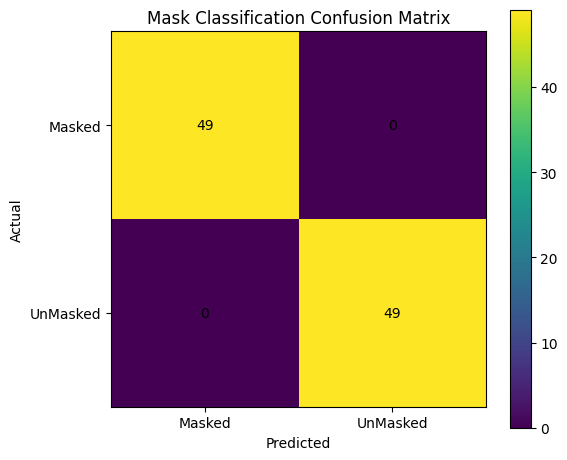

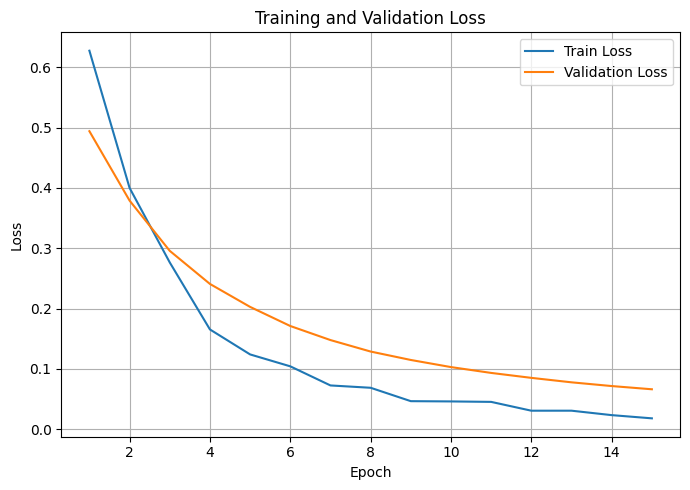

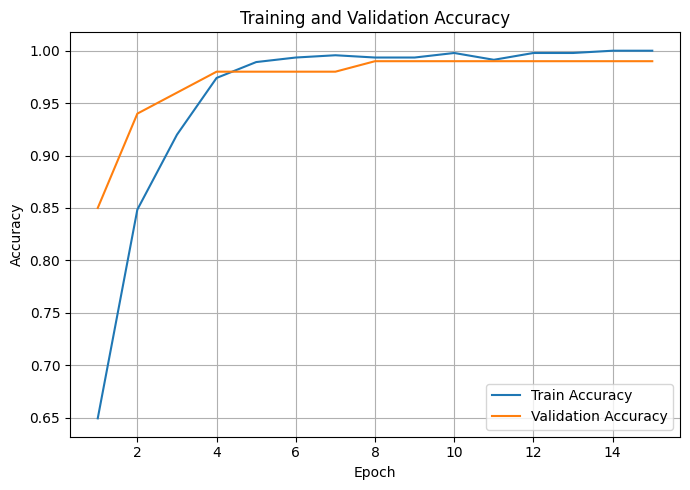


All results saved in:
/kaggle/working/mask_mobilenetv2/Mask Detection/Model Evaluation


In [35]:
# Confusion matrix
cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("Mask Classification Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1],class_names)

plt.yticks([0, 1],class_names)

for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i, j],ha="center",va="center")

plt.colorbar()
plt.tight_layout()

plt.savefig(os.path.join(MODEL_DIR,"Mask Detection","Model Evaluation", "confusion_matrix.png"),dpi=300)

plt.show()

'''
Training Curves
'''

hist = history.history
epochs = range(1,len(hist["loss"]) + 1)

# Training loss

plt.figure(figsize=(7, 5))

plt.plot(epochs,hist["loss"],label="Train Loss")

plt.plot(epochs,hist["val_loss"],label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(os.path.join(MODEL_DIR,"Mask Detection","Model Evaluation", "loss_curve.png"),dpi=300)

plt.show()

# Training accuracy

plt.figure(figsize=(7, 5))

plt.plot(epochs,hist["accuracy"],label="Train Accuracy")

plt.plot(epochs,hist["val_accuracy"],label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(os.path.join(MODEL_DIR,"Mask Detection","Model Evaluation", "accuracy_curve.png"),dpi=300)

plt.show()

# Saving results

results_df = pd.DataFrame({"true_label": y_true,"predicted_label": y_pred,"probability_unmasked": y_prob})

results_df.to_csv(os.path.join(MODEL_DIR,"Mask Detection","Model Evaluation", "test_predictions.csv"),index=False)

print("\nAll results saved in:")
print(MODEL_DIR+"/Mask Detection/Model Evaluation")


## Identity Matching model

In [36]:

MODEL_DIR = "/kaggle/working/mask_mobilenetv2/identity_siamese"
os.makedirs(MODEL_DIR, exist_ok=True)

EMBEDDING_DIM = 256

MARGIN = 1.0

EPOCHS = 50

# L2 normalization

@tf.keras.utils.register_keras_serializable()
class L2Normalize(tf.keras.layers.Layer):

    def call(self, inputs):

        return tf.math.l2_normalize(
            inputs,
            axis=1
        )

# Euclidien distance layer

@tf.keras.utils.register_keras_serializable()
class EuclideanDistance(tf.keras.layers.Layer):

    def call(self, inputs):

        x1, x2 = inputs

        return tf.sqrt(
            tf.reduce_sum(
                tf.square(x1 - x2),
                axis=1,
                keepdims=True
            ) + 1e-8
        )

# Embedding Network

def build_embedding_model():

    inputs = tf.keras.Input(
        shape=(224, 224, 3),
        name="upper_face_input"
    )

    # Pretrained MobileNetV2

    backbone = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )


    backbone.trainable = True

    # [0,1] -> [-1,1]

    x = tf.keras.layers.Rescaling(
        scale=2.0,
        offset=-1.0,
        name="mobilenet_input_scaling"
    )(inputs)

    x = backbone(x,training=False)

    # Feature aggregation

    x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)


    x = tf.keras.layers.Dense(EMBEDDING_DIM,activation="relu",
                              name="embedding_dense")(x)

    # L2 Normalization

    x = L2Normalize(name="embedding")(x)

    return tf.keras.Model(inputs,x,name="MobileNetV2_UpperFace_Embedding")


embedding_model = build_embedding_model()



# Siamese network

image_a = tf.keras.Input(shape=(224, 224, 3),name="image_a")

image_b = tf.keras.Input(shape=(224, 224, 3),name="image_b")


embedding_a = embedding_model(image_a)

embedding_b = embedding_model(image_b)



distance = EuclideanDistance(name="distance")([embedding_a, embedding_b])


siamese_model = tf.keras.Model([image_a, image_b],distance,name="SiameseIdentityModel")


# CONTRASTIVE LOSS


@tf.keras.utils.register_keras_serializable()
def contrastive_loss(y_true, y_pred):

    y_true = tf.cast(tf.reshape(y_true,(-1, 1)),tf.float32)

    # If same identity

    positive_loss = (y_true *tf.square(y_pred))

    # If different identity

    negative_loss = ((1.0 - y_true) *tf.square(tf.maximum(MARGIN - y_pred,0.0)))

    return tf.reduce_mean(positive_loss +negative_loss)


# Model compilation

siamese_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LR
    ),
    loss=contrastive_loss
)

# Model summary
siamese_model.summary()


print("\nEmbedding backbone trainable:",embedding_model.get_layer(index=2).trainable)

print("Embedding dimension:",EMBEDDING_DIM)

print("Margin:",MARGIN)

print("Learning rate:",LR)


Model: "SiameseIdentityModel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_a             │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_b             │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_UpperF… │ (None, 256)       │  2,585,920 │ image_a[0][0],    │
│ (Functional)        │                   │            │ image_b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ distance            │ (None, 1)         │          0 │ MobileNetV2_Uppe… │
│ (EuclideanDistance) │                   │            │ MobileNetV2_Uppe… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,585,920 (9.86 MB)

 Trainable params: 2,551,808 (9.73 MB)

 Non-trainable params: 34,112 (133.25 KB)


Embedding backbone trainable: True
Embedding dimension: 256
Margin: 1.0
Learning rate: 1e-05


### Training

Epoch 1/50


2026-11-05 19:56:27.526748: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 19:56:27.665096: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793908609.341728     189 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - loss: 0.3547

2026-11-05 19:57:24.069240: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 19:57:24.206532: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 771ms/step - loss: 0.3543

2026-11-05 19:58:06.018059: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 19:58:06.155340: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.35139, saving model to /kaggle/working/mask_mobilenetv2/identity_siamese/best_siamese.weights.h5

Epoch 1: finished saving model to /kaggle/working/mask_mobilenetv2/identity_siamese/best_siamese.weights.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - loss: 0.3254 - val_loss: 0.3514 - learning_rate: 1.0000e-05
Epoch 2/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - loss: 0.2760
Epoch 2: val_loss improved from 0.35139 to 0.31870, saving model to /kaggle/working/mask_mobilenetv2/identity_siamese/best_siamese.weights.h5

Epoch 2: finished saving model to /kaggle/working/mask_mobilenetv2/identity_siamese/best_siamese.weights.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 18s 249ms/step - loss: 0.2696 - val_loss: 0.3187 - learning_rate: 1.0000e-05
Epoch 3/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - loss: 0.2463
Epoch 3: val_loss improved from 0.31870 to 0.29884, saving model to /kaggle/working/mask_mobilenetv2/identity_siamese/best_siamese.weights.h5

Epoch 3: finished

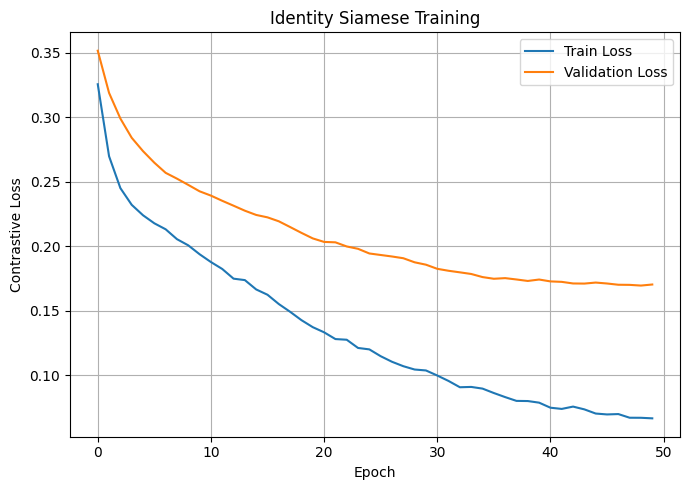


Training complete.
Best weights: /kaggle/working/mask_mobilenetv2/identity_siamese/best_siamese.weights.h5


In [37]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    os.path.join(MODEL_DIR,"best_siamese.weights.h5"),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Training

history = siamese_model.fit(
    identity_train_ds,
    validation_data=identity_valid_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

# Loading the best model

siamese_model.load_weights(os.path.join(MODEL_DIR,"best_siamese.weights.h5"))
siamese_model.save(os.path.join(MODEL_DIR, "best_siamese.keras"))

# Saving model history

history_df = pd.DataFrame(history.history)

history_df.to_csv(os.path.join(MODEL_DIR,"training_history.csv"),index=False)

# Training curve

plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"],label="Train Loss")

plt.plot(history.history["val_loss"],label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Contrastive Loss")
plt.title("Identity Siamese Training")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(os.path.join(MODEL_DIR,"training_loss.png"),dpi=200,bbox_inches="tight")

plt.show()

print("\nTraining complete.")
print("Best weights:",os.path.join(MODEL_DIR,"best_siamese.weights.h5"))


## Identity Matching model Evaluation

2026-11-05 20:14:07.226546: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 20:14:07.369373: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Validation pairs: 492
Test pairs: 474

IDENTITY VERIFICATION RESULTS

Validation-selected threshold : 0.8195
Validation F1                 : 0.7984

-----------------------------------------------------------------
TEST RESULTS
-----------------------------------------------------------------
Metric                Validation Threshold      Fixed 0.5
-----------------------------------------------------------------
Threshold                           0.8195         0.5000
Accuracy                            0.7637         0.6392
Precision                           0.7451         0.5842
Recall                              0.8017         0.9662
F1-score                            0.7724         0.7281
FAR                                 0.2743         0.6878

CLASSIFICATION REPORT

--- Validation-selected threshold ---

                    precision    recall  f1-score   support

Different Identity       0.79      0.73      0.75       237
     Same Identity       0.75      0.80      0.77 

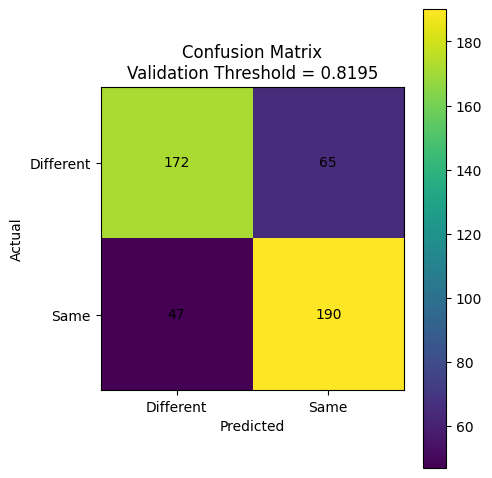

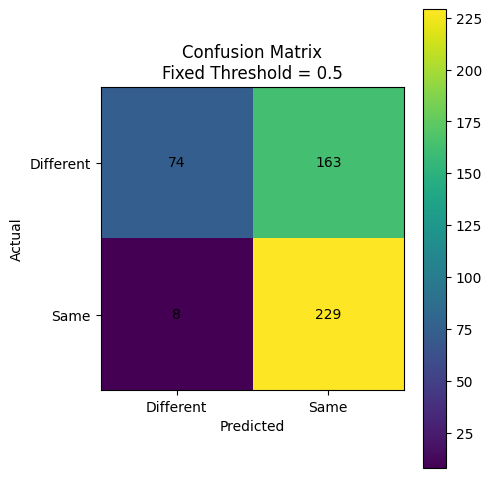


Results saved to: /kaggle/working/mask_mobilenetv2/identity_siamese Model Evaluation/


In [39]:

# COSINE SIMILARITY EXTRACTION


def get_cosine_similarities(dataset):

    similarities = []
    labels = []

    for (img_a, img_b), y in dataset:

        # Get normalized embeddings directly
        emb_a = embedding_model.predict(img_a, verbose=0)

        emb_b = embedding_model.predict(img_b, verbose=0)

        # Cosine similarity
        sim = np.sum(emb_a * emb_b, axis=1)

        similarities.extend(sim)

        labels.extend(y.numpy().reshape(-1))

    return (
        np.array(similarities),
        np.array(labels).astype(int)
    )

os.makedirs(
    os.path.join(MODEL_DIR, "Model Evaluation"),
    exist_ok=True
)

# Validation and test similarity

val_similarities, val_labels = get_cosine_similarities(
    identity_valid_ds
)

test_similarities, test_labels = get_cosine_similarities(
    identity_test_ds
)

print("Validation pairs:", len(val_labels))
print("Test pairs:", len(test_labels))


# VALIDATION THRESHOLD SELECTION

thresholds = np.linspace(-1.0, 1.0, 400)

best_threshold = 0.0
best_f1 = -1.0

for threshold in thresholds:

    val_predictions = (
        val_similarities >= threshold
    ).astype(int)

    score = f1_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    if score > best_f1:

        best_f1 = score
        best_threshold = threshold


# EVALUATION FUNCTION

def evaluate_threshold(similarities, labels, threshold):

    predictions = (
        similarities >= threshold
    ).astype(int)

    accuracy = accuracy_score(labels, predictions)

    precision = precision_score(
        labels, predictions, zero_division=0
    )

    recall = recall_score(
        labels, predictions, zero_division=0
    )

    f1 = f1_score(
        labels, predictions, zero_division=0
    )

    cm = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    )

    # Extract confusion matrix values
    TN, FP, FN, TP = cm.ravel()

    # False Acceptance Rate
    FAR = FP / (FP + TN) if (FP + TN) > 0 else 0.0

    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "FAR": float(FAR),
        "confusion_matrix": cm,
        "predictions": predictions
    }


# 1. VALIDATION-SELECTED THRESHOLD

validation_threshold_results = evaluate_threshold(
    test_similarities,
    test_labels,
    best_threshold
)


# 2. FIXED 0.5 THRESHOLD=

fixed_threshold = 0.5

fixed_threshold_results = evaluate_threshold(
    test_similarities,
    test_labels,
    fixed_threshold
)


# PRINT COMPARISON

print("\n" + "=" * 65)
print("IDENTITY VERIFICATION RESULTS")
print("=" * 65)

print(
    f"\nValidation-selected threshold : "
    f"{best_threshold:.4f}"
)

print(
    f"Validation F1                 : "
    f"{best_f1:.4f}"
)

print("\n" + "-" * 65)
print("TEST RESULTS")
print("-" * 65)

print(
    f"{'Metric':<20}"
    f"{'Validation Threshold':>22}"
    f"{'Fixed 0.5':>15}"
)

print("-" * 65)

print(
    f"{'Threshold':<20}"
    f"{best_threshold:>22.4f}"
    f"{fixed_threshold:>15.4f}"
)

print(
    f"{'Accuracy':<20}"
    f"{validation_threshold_results['accuracy']:>22.4f}"
    f"{fixed_threshold_results['accuracy']:>15.4f}"
)

print(
    f"{'Precision':<20}"
    f"{validation_threshold_results['precision']:>22.4f}"
    f"{fixed_threshold_results['precision']:>15.4f}"
)

print(
    f"{'Recall':<20}"
    f"{validation_threshold_results['recall']:>22.4f}"
    f"{fixed_threshold_results['recall']:>15.4f}"
)

print(
    f"{'F1-score':<20}"
    f"{validation_threshold_results['f1']:>22.4f}"
    f"{fixed_threshold_results['f1']:>15.4f}"
)

print(
    f"{'FAR':<20}"
    f"{validation_threshold_results['FAR']:>22.4f}"
    f"{fixed_threshold_results['FAR']:>15.4f}"
)


# CLASSIFICATION REPORTS

target_names = [
    "Different Identity",
    "Same Identity"
]

print("\n" + "=" * 65)
print("CLASSIFICATION REPORT")
print("=" * 65)

print(
    "\n--- Validation-selected threshold ---\n"
)

report_validation = classification_report(
    test_labels,
    validation_threshold_results["predictions"],
    target_names=target_names,
    zero_division=0
)

print(report_validation)

print(
    "\n--- Fixed threshold = 0.5 ---\n"
)

report_fixed = classification_report(
    test_labels,
    fixed_threshold_results["predictions"],
    target_names=target_names,
    zero_division=0
)

print(report_fixed)


# CONFUSION MATRICES

print("\n" + "=" * 65)
print("CONFUSION MATRICES")
print("=" * 65)

cm_validation = (
    validation_threshold_results["confusion_matrix"]
)

cm_fixed = (
    fixed_threshold_results["confusion_matrix"]
)

print(
    "\nValidation-selected threshold:"
)

print(cm_validation)

print(
    "\nFixed threshold = 0.5:"
)

print(cm_fixed)


# PLOT VALIDATION-THRESHOLD CONFUSION MATRIX

plt.figure(figsize=(5, 5))

plt.imshow(cm_validation)

plt.title(
    f"Confusion Matrix\n"
    f"Validation Threshold = {best_threshold:.4f}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Different", "Same"]
)

plt.yticks(
    [0, 1],
    ["Different", "Same"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm_validation[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(
        MODEL_DIR,  "Model Evaluation",
        "confusion_matrix_validation_threshold.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# PLOT FIXED 0.5 CONFUSION MATRIX

plt.figure(figsize=(5, 5))

plt.imshow(cm_fixed)

plt.title(
    "Confusion Matrix\n"
    "Fixed Threshold = 0.5"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Different", "Same"]
)

plt.yticks(
    [0, 1],
    ["Different", "Same"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm_fixed[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(
        MODEL_DIR, "Model Evaluation",
        "confusion_matrix_threshold_0.5.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# SAVE METRICS

results = {

    "similarity_metric":
        "cosine_similarity",

    "validation_threshold": {

        "threshold":
            float(best_threshold),

        "validation_f1":
            float(best_f1),

        "test_accuracy":
            validation_threshold_results["accuracy"],

        "test_precision":
            validation_threshold_results["precision"],

        "test_recall":
            validation_threshold_results["recall"],

        "test_f1":
            validation_threshold_results["f1"],

        "test_FAR":
            validation_threshold_results["FAR"]
    },

    "fixed_threshold_0.5": {

        "threshold":
            float(fixed_threshold),

        "test_accuracy":
            fixed_threshold_results["accuracy"],

        "test_precision":
            fixed_threshold_results["precision"],

        "test_recall":
            fixed_threshold_results["recall"],

        "test_f1":
            fixed_threshold_results["f1"],

        "test_FAR":
            fixed_threshold_results["FAR"]
    }
}


with open(
    os.path.join(
        MODEL_DIR, "Model Evaluation",
        "identity_results.json"
    ),
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )


# SAVE TEST PREDICTIONS

test_results_df = pd.DataFrame({

    "true_label":
        test_labels,

    "cosine_similarity":
        test_similarities,

    "prediction_validation_threshold":
        validation_threshold_results["predictions"],

    "prediction_threshold_0.5":
        fixed_threshold_results["predictions"]
})


test_results_df.to_csv(
    os.path.join(
        MODEL_DIR, "Model Evaluation",
        "test_predictions.csv"
    ),
    index=False
)


print(
    "\nResults saved to:",
    MODEL_DIR,"Model Evaluation/"
)


# Unified model export (Mask Detection + Identity Matching)
This combines the trained mask classifier and Siamese identity model into one Keras model with three inputs and two outputs.

In [40]:
# Build a unified inference model from two independently trained models.


# 1. LOAD TRAINED MASK CLASSIFICATION MODEL

MODEL_DIR = "/kaggle/working/mask_mobilenetv2"
os.makedirs(
    os.path.join(MODEL_DIR, "Unified Model"),
    exist_ok=True
)

MASK_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "Mask Detection",
    "best_mask_detector_model.keras"
)

best_model = tf.keras.models.load_model(
    MASK_MODEL_PATH,
    compile=False
)

print("Mask classification model loaded.")


# 2. LOAD TRAINED SIAMESE MODEL

SIAMESE_MODEL_PATH = os.path.join(
    MODEL_DIR,"identity_siamese",
    "best_siamese.keras"
)

siamese_model = tf.keras.models.load_model(
    SIAMESE_MODEL_PATH,
    custom_objects={
        "L2Normalize": L2Normalize
    },
    compile=False
)

print("Siamese model loaded.")


# 3. DEFINE TWO INPUT IMAGES

image_a = tf.keras.Input(
    shape=(224, 224, 3),
    name="image_a"
)

image_b = tf.keras.Input(
    shape=(224, 224, 3),
    name="image_b"
)


# 4. MASK CLASSIFICATION BRANCH

mask_probability_a = best_model(
    image_a,
    training=False
)

mask_probability_b = best_model(
    image_b,
    training=False
)


# 5. IDENTITY VERIFICATION BRANCH

identity_distance = siamese_model(
    [image_a, image_b],
    training=False
)


# 6. CONSTRUCT UNIFIED MODEL

unified_model = tf.keras.Model(
    inputs=[image_a, image_b],
    outputs=[
        mask_probability_a,
        mask_probability_b,
        identity_distance
    ],
    name="Unified_Mask_Identity_Model"
)


# 7. DISPLAY MODEL ARCHITECTURE

unified_model.summary()


# 8. SAVE COMPLETE UNIFIED MODEL

UNIFIED_MODEL_PATH = os.path.join(
    MODEL_DIR, "Unified Model", 
    "unified_model.keras"
)

unified_model.save(UNIFIED_MODEL_PATH)

print("\nUnified model saved successfully.")
print("Model path:", UNIFIED_MODEL_PATH)

Mask classification model loaded.
Siamese model loaded.


Model: "Unified_Mask_Identity_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_a             │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_b             │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MaskMobileNetV2     │ (None, 1)         │  2,259,265 │ image_a[0][0],    │
│ (Functional)        │                   │            │ image_b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SiameseIdentityMod… │ (None, 1)         │  2,585,920 │ image_a[0][0],    │
│ (Functional)        │                   │            │ image_b[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,845,185 (18.48 MB)

 Trainable params: 4,776,961 (18.22 MB)

 Non-trainable params: 68,224 (266.50 KB)


Unified model saved successfully.
Model path: /kaggle/working/mask_mobilenetv2/Unified Model/unified_model.keras
